In [2]:
import torch
import lightning as L
from lightning.pytorch.utilities.model_summary import ModelSummary
import xarray as xr

from matplotlib import pyplot as plt
import numpy as np
import importlib
from data_functions import dataset, utils_data
from src import LTAE, UTAE, lightning_module, utils_model, metrics

PATH_TO_DATA_s2 = "/home/hkerino/Documents/nextoso-dataset/data/10m/s2"
PATH_TO_DATA_label = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"
PATH_TO_OSO_CLASSES = "/home/hkerino/Documents/nextoso-dataset/data/auxiliary/OSO/oso_classes.csv"

In [3]:
importlib.reload(dataset)
dt = dataset.next_oso_Dataset(
    path_s2=PATH_TO_DATA_s2, path_label=PATH_TO_DATA_label, path_oso_class=PATH_TO_OSO_CLASSES, norm=False, remove_invalid_temp=True,folds=None
)

batch_size = 2

dl_train, dl_val, dl_test = dataset.get_loaders(
    path_s2=PATH_TO_DATA_s2,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    folds_train=[1],
    folds_val=[2],
    folds_test=[3],
    batch_size=batch_size,
    num_worker=4,
    norm=True,
    shuffle=True,
)

In [4]:
(x, dates, mask), y = dl_train.__iter__().__next__()
print(x.shape)
print(dates.shape)
print(mask.shape)
print(y.shape)


torch.Size([2, 10, 55, 128, 128])
torch.Size([2, 55])
torch.Size([2, 55, 128, 128])
torch.Size([2, 128, 128])


(<Figure size 1500x800 with 10 Axes>, <Figure size 800x800 with 2 Axes>)

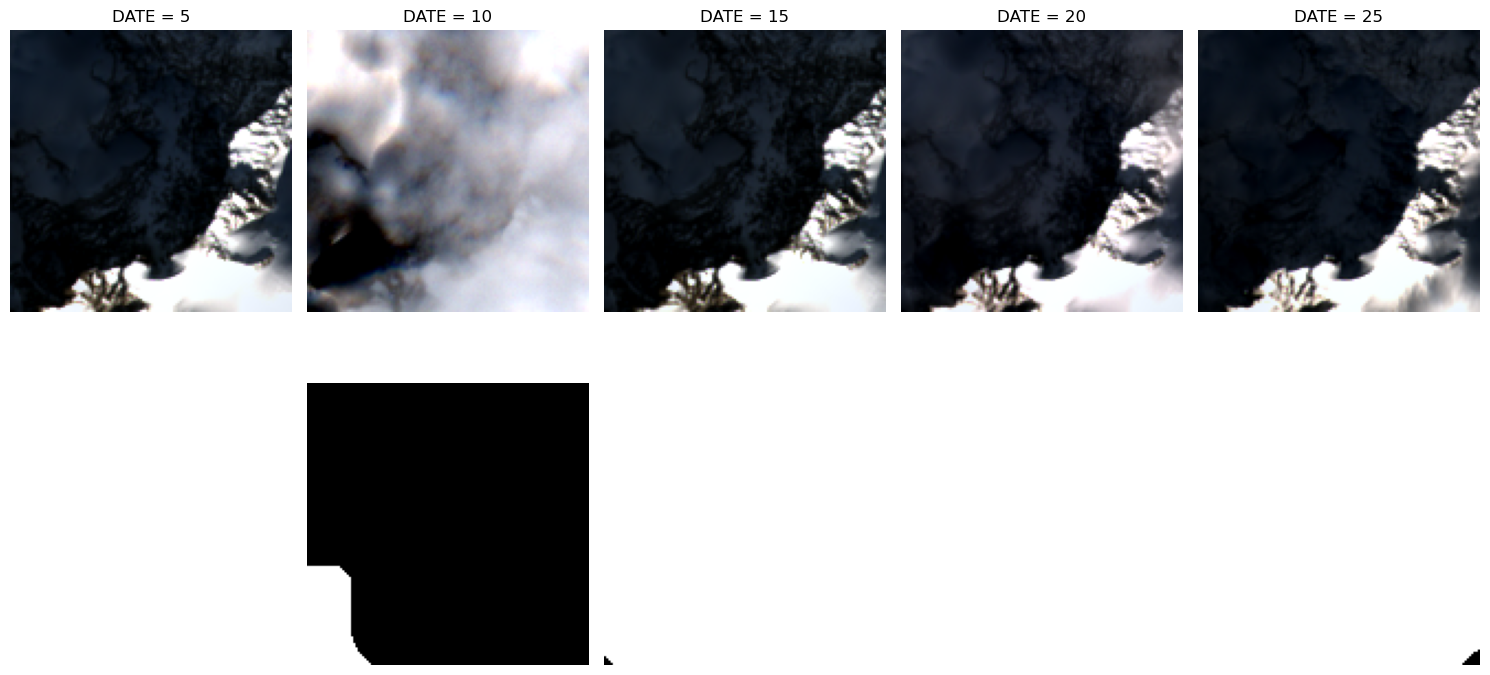

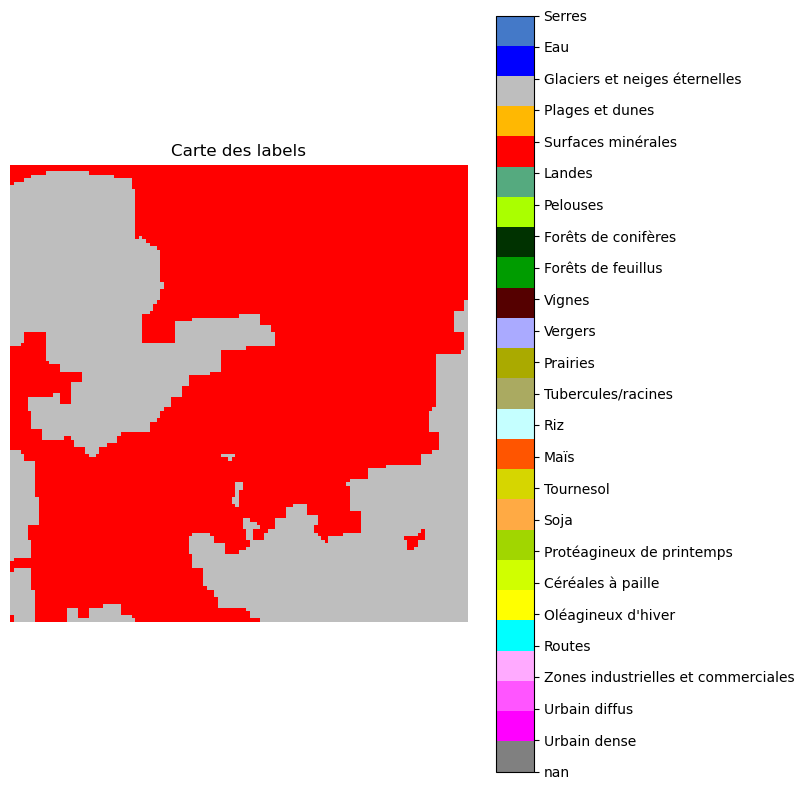

In [3]:
utils_data.plot_nextoso(dt, idx=160, first_date=0)

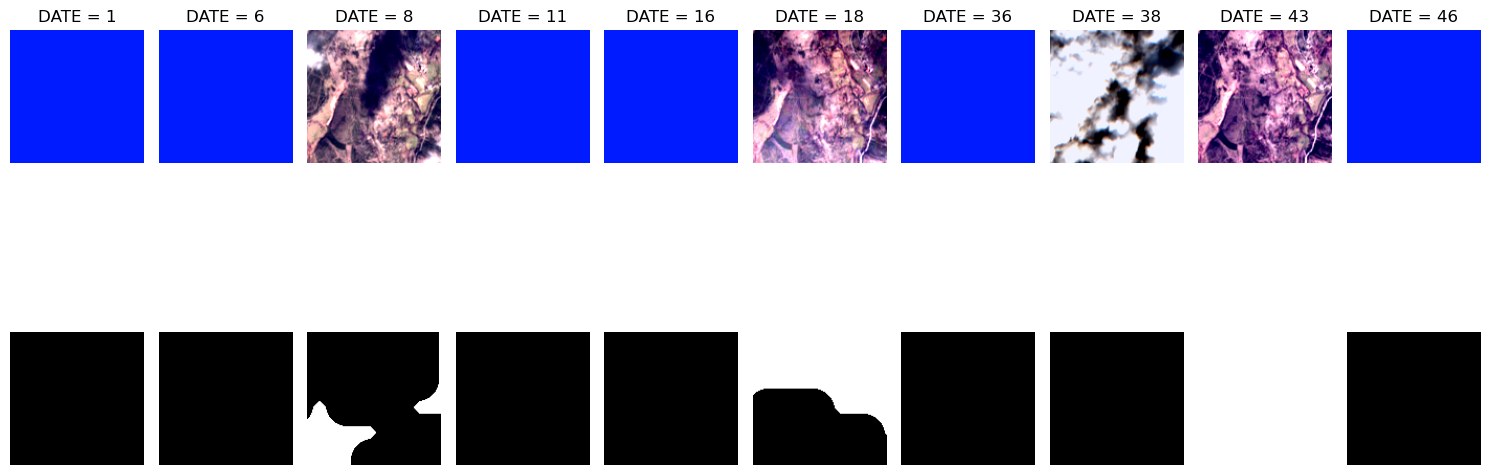

In [82]:
idx_batch = 0
lenght, first_date = 10, 0
fig, axes1 = plt.subplots(2,lenght, figsize=(15,8))
for t in range(lenght):
    # Affichage de l'image RGB
    axes1[0, t].imshow(utils_data.array_to_RGB(x[idx_batch, :,first_date + t, :, :], norm=True))
    axes1[0, t].set_title(f"DATE = {dates[idx_batch, first_date + t].numpy()}")
    axes1[0, t].axis("off")
    # Affichage du masque
    axes1[1, t].imshow(
        mask[idx_batch, first_date + t, :, :], cmap="Greys", vmin=0, vmax=1
    )
    axes1[1, t].axis("off")
plt.tight_layout()

In [85]:
utils_data.array_to_RGB(x[idx_batch, :, 0, :, :])

array([[[0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        ...,
        [0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ]],

       [[0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        ...,
        [0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ]],

       [[0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        ...,
        [0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ]],

       ...,

       [[0.        , 0.10841123, 1.        ],
        [0.        , 0.10841123, 1.        ],
        [0.        , 0

In [ ]:
LTAE_encoder = LTAE.LTAE2d(
    in_channels=10,
    n_head=16,
    d_k=8,
    d_model=128,
    T=1000,
    return_att=False,
    positional_encoding=True,
)
UTAE_encoder = UTAE.UTAE(
        input_dim = 10,
        encoder_widths=[64, 64, 64, 128],
        decoder_widths=[32, 32, 64, 128],
        out_conv=[32, 20],
        str_conv_k=4,
        str_conv_s=2,
        str_conv_p=1,
        agg_mode="att_group",
        encoder_norm="group",
        n_head=16,
        d_model=256,
        d_k=4,
        encoder=True,
        return_maps=True,
        pad_value=0,
        padding_mode="reflect",
    )

MLP_Decoder = utils_model.MLPDecoder(mlp=[128, 64, 25], dropout=0.2)

In [32]:
importlib.reload(lightning_module)

classifier = lightning_module.classifier(UTAE_encoder, MLP_Decoder, batch_size=batch_size, loss_fn=torch.nn.CrossEntropyLoss(), mask_need=False)
summary = ModelSummary(classifier, max_depth=-1)
print(summary)

    | Name                                                       | Type                      | Params | Mode  | FLOPs
---------------------------------------------------------------------------------------------------------------------------
0   | encoder                                                    | UTAE                      | 1.1 M  | eval  | 0    
1   | encoder.in_conv                                            | ConvBlock                 | 43.0 K | eval  | 0    
2   | encoder.in_conv.conv                                       | ConvLayer                 | 43.0 K | eval  | 0    
3   | encoder.in_conv.conv.conv                                  | Sequential                | 43.0 K | eval  | 0    
4   | encoder.in_conv.conv.conv.0                                | Conv2d                    | 5.8 K  | eval  | 0    
5   | encoder.in_conv.conv.conv.1                                | GroupNorm                 | 128    | eval  | 0    
6   | encoder.in_conv.conv.conv.2                 

In [33]:
trainer = L.Trainer(
    max_epochs=1, profiler="simple", limit_train_batches=1, limit_val_batches=1, limit_test_batches=1
)
trainer.fit(model=classifier, train_dataloaders=dl_train, val_dataloaders=dl_val)
trainer.test(model=classifier, dataloaders=dl_test)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1)` was configured so 1 batch per epoch will be used.
`Trainer(limit_val_batches=1)` was configured so 1 batch will be used.
`Trainer(limit_test_batches=1)` was configured so 1 batch will be used.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name           | Type                      | Params | Mode  | FLOPs
-----------------------------------------------------------------------------
0 | encoder        | UTAE                      | 1.1 M  | eval  | 0    
1 | decoder        | MLPDecoder          

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


RuntimeError: Given groups=1, weight of size [64, 10, 3, 3], expected input[20, 148, 130, 130] to have 10 channels, but got 148 channels instead

torch.Size([10, 10])


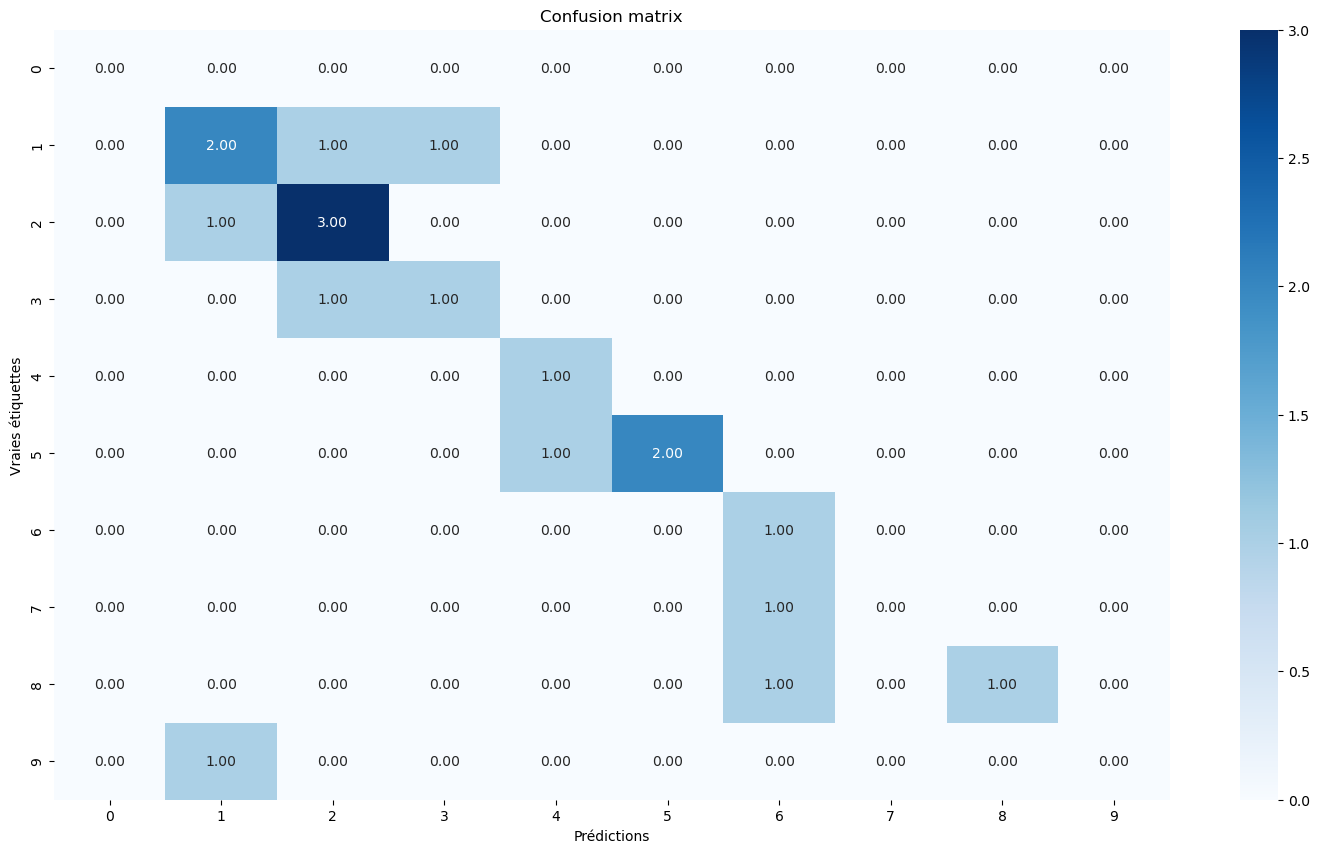

In [21]:
from torchmetrics.classification import MulticlassF1Score, MulticlassConfusionMatrix
from torchmetrics.segmentation import MeanIoU

miou = MeanIoU(num_classes=10, include_background=False, input_format='index')
f = MulticlassF1Score(num_classes=10,ignore_index=0)
cm = MulticlassConfusionMatrix(num_classes=10,ignore_index=0,normalize="none")
label = torch.Tensor([0,1,2,3,4,5,5,5,6,7,8,8,9,0,1,2,1,2,1,2,3])
preds = torch.Tensor([1,1,2,3,4,5,4,5,6,6,6,8,1,8,2,2,1,2,3,1,2])



r_cm = cm(preds,label)

print(r_cm.shape)

fig_cm = metrics.convert_cm_to_figure(r_cm)

In [22]:
print(miou(preds.long(),label.long()))
print(metrics.calculate_miou(preds, label, n_classes=10))

tensor(0.3280)
0.3518517315387726


In [35]:
(x, dates, mask), y = dl_val.__iter__().__next__()
print(x.shape)
print(dates.shape)
print(mask.shape)
print(y.shape)

torch.Size([2, 10, 148, 128, 128])
torch.Size([2, 148])
torch.Size([2, 148, 128, 128])
torch.Size([2, 128, 128])


In [80]:
importlib.reload(UTAE)
UTAE_encoder = UTAE.UTAE(
    input_dim=10,
    encoder_widths=[64, 64, 64, 128],
    decoder_widths=[32, 32, 64, 128],
    out_conv=[32, 20],
    str_conv_k=4,
    str_conv_s=2,
    str_conv_p=1,
    agg_mode="att_group",
    encoder_norm="group",
    n_head=8,
    d_model=128,
    d_k=4,
    encoder=True,
    return_maps=False,
    pad_value=0,
    padding_mode="reflect",
)

In [81]:
x_modif = x.permute(0, 2, 1, 3, 4).contiguous()
print(x_modif.shape)
out = UTAE_encoder(x_modif, dates)

torch.Size([2, 148, 10, 128, 128])
tensor([[False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False, False,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  

In [79]:
out[0].shape

torch.Size([2, 32, 128, 128])

## Analyse model

In [14]:
LTAE_encoder = LTAE.LTAE2d(
    in_channels=10,
    n_head=16,
    d_k=8,
    d_model=128,
    T=1000,
    return_att=False,
    positional_encoding=True,
)
# Decoder
MLP_Decoder = utils_model.MLPDecoder(mlp=[128, 64, 25], dropout=0.2)

alpha_weights = torch.from_numpy(np.load("./data_functions/alpha_weights.npy"))
criterion_fl = metrics.FocalLoss(alpha=alpha_weights, gamma=2, ignore_index=0)

best_classifier = lightning_module.classifier.load_from_checkpoint(
    "/home/hkerino/Documents/next_oso/logs/light_training/LTAE_2026-03-03/Checkpoints/epoch=6-step=3745.ckpt",
    weights_only=True,
    encoder=LTAE_encoder,
    decoder=MLP_Decoder,
    loss_fn=criterion_fl,
    batch_size=4,
)

random_classifier = lightning_module.classifier(
    LTAE_encoder,
    MLP_Decoder,
    batch_size=4,
    loss_fn=criterion_fl,
    lr=1e-2,
)

In [60]:
best_classifier = lightning_module.classifier(
    encoder=LTAE_encoder, decoder=MLP_Decoder, loss_fn=criterion_fl, batch_size=4
)
checkpoint = torch.load(
    "/home/hkerino/Documents/next_oso/logs/light_training/LTAE_2026-03-03/Checkpoints/epoch=6-step=3745.ckpt",
    map_location=torch.device("cpu"),
)
best_classifier.load_state_dict(checkpoint["state_dict"])

<All keys matched successfully>

In [58]:
trainer = L.Trainer()
trainer.test(model=best_classifier, dataloaders=dl_test)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Testing: |          | 0/? [00:00<?, ?it/s]


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3709: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [55]:
dl_test.__iter__().__next__()


((tensor([[[[[ 3.6845e-01,  3.8038e-01,  3.7692e-01,  ...,  1.7315e-01,
               1.6866e-01,  1.8561e-01],
             [ 3.6706e-01,  3.6983e-01,  3.7658e-01,  ...,  1.8976e-01,
               1.8492e-01,  1.7160e-01],
             [ 3.6758e-01,  3.6620e-01,  3.9094e-01,  ...,  1.1988e-01,
               1.4513e-01,  1.7212e-01],
             ...,
             [ 4.2069e-01,  5.5181e-01,  7.4624e-01,  ...,  1.2109e-01,
               1.1399e-01,  1.2057e-01],
             [ 1.8855e-01,  2.6414e-01,  4.2847e-01,  ...,  1.4842e-01,
               1.3596e-01,  1.2316e-01],
             [ 1.6243e-01,  1.7298e-01,  2.2124e-01,  ...,  1.6762e-01,
               1.4859e-01,  1.3423e-01]],
  
            [[ 3.9388e-01,  4.0841e-01,  4.1619e-01,  ...,  2.1917e-01,
               2.2245e-01,  2.2020e-01],
             [ 3.8644e-01,  4.0097e-01,  4.0477e-01,  ...,  2.1000e-01,
               2.1052e-01,  2.0100e-01],
             [ 3.9768e-01,  3.8540e-01,  3.9889e-01,  ...,  1.9184e-01,
  

In [61]:
fc1_k_weights = best_classifier.encoder.attention_heads.fc1_k.weight
#fc1_k_weights = random_classifier.encoder.attention_heads.fc1_k.weight

fc1_k_bias = best_classifier.encoder.attention_heads.fc1_k.bias
#fc1_k_bias = random_classifier.encoder.attention_heads.fc1_k.bias

In [62]:
print("Moyenne des poids de fc1_k :", fc1_k_weights.mean().item())
print("Écart-type des poids de fc1_k :", fc1_k_weights.std().item())
print("Valeur minimale des poids de fc1_k :", fc1_k_weights.min().item())
print("Valeur maximale des poids de fc1_k :", fc1_k_weights.max().item())

Moyenne des poids de fc1_k : 0.016803469508886337
Écart-type des poids de fc1_k : 0.5966291427612305
Valeur minimale des poids de fc1_k : -3.7002270221710205
Valeur maximale des poids de fc1_k : 2.963665008544922


In [28]:
print(fc1_k_bias)

Parameter containing:
tensor([-0.2826, -0.1316,  0.0521, -0.3401,  0.1092,  0.3569, -0.3623,  0.1847,
         1.5921, -1.4384, -0.7386, -1.7028, -2.0471,  1.9382, -1.9020,  0.6456,
        -2.0057,  1.6865, -0.9347,  0.3112, -1.4652, -0.2113,  1.9350, -0.6870,
        -0.0525, -3.8446,  2.8255,  1.2033, -2.0300, -4.0744, -0.8235, -2.0647,
        -0.8368, -0.4018,  0.3518,  0.5308, -0.0392, -0.3034,  0.5065,  0.7947,
        -1.6013, -1.4035,  1.5157,  1.8127, -1.2580, -2.2166, -0.7960,  1.9608,
         0.5530, -0.0909,  0.3758,  0.6923, -0.0332, -0.1482,  0.1334, -0.7501,
        -0.9837,  0.6427, -0.4173,  0.9459,  1.0377,  0.7341,  0.5715, -0.3359,
         1.2623, -1.2669, -0.6346,  0.5100,  0.9105,  0.1857, -1.0379,  1.4316,
         0.1250,  0.8253,  0.6509, -0.7522, -0.4780, -0.0222, -0.7735,  0.1540,
        -0.2854,  0.8283, -0.2603,  0.1393, -0.3494, -0.8944, -0.3861,  0.1871,
         0.1988, -0.7142,  0.8770,  0.5687,  0.6903, -0.2376, -0.0598, -0.2229,
        -0.5406, -

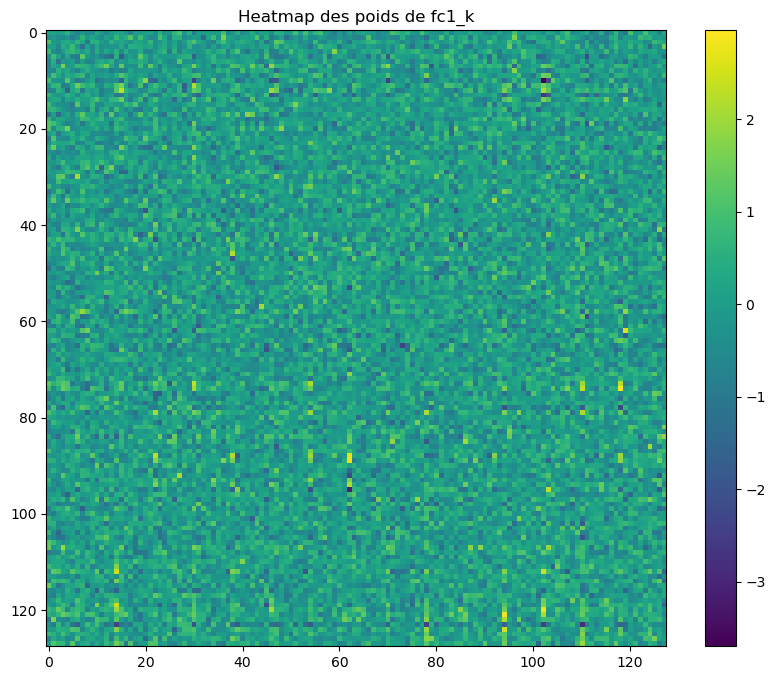

In [22]:
# Heatmap des poids de fc1_k
plt.figure(figsize=(10, 8))
plt.imshow(fc1_k_weights.detach().numpy(), cmap="viridis", aspect="auto")
plt.colorbar()
plt.title("Heatmap des poids de fc1_k")
plt.show()

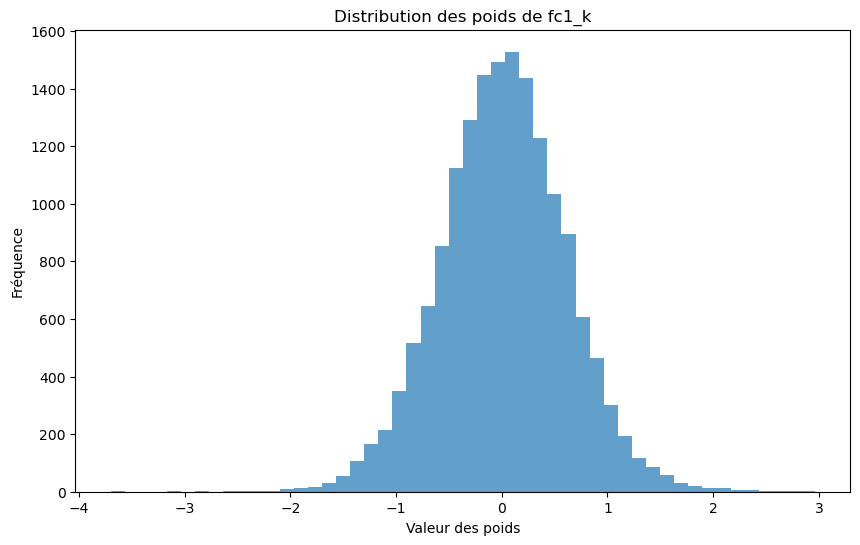

In [63]:
# Histogramme des poids de fc1_k
plt.figure(figsize=(10, 6))
plt.hist(fc1_k_weights.detach().numpy().flatten(), bins=50, alpha=0.7)
plt.title("Distribution des poids de fc1_k")
plt.xlabel("Valeur des poids")
plt.ylabel("Fréquence")
plt.show()

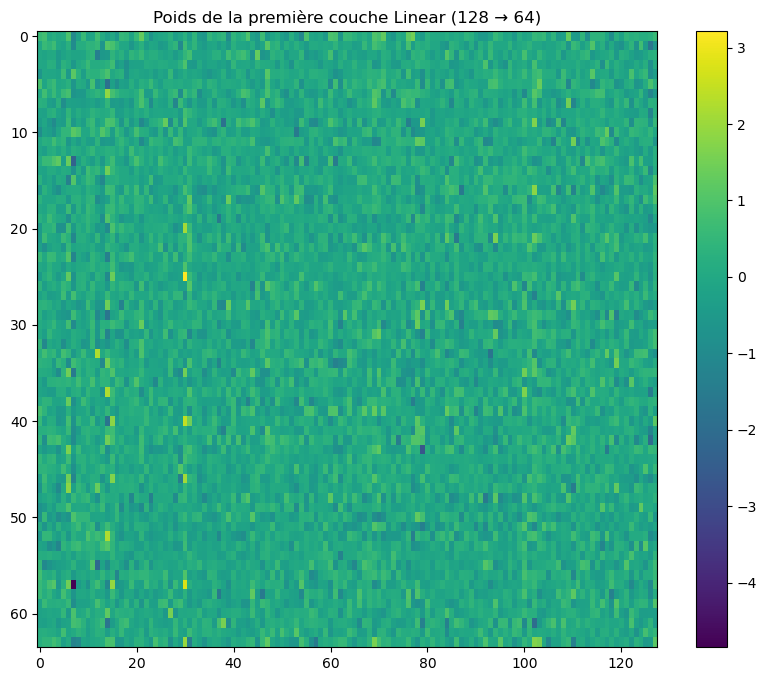

In [37]:
# Visualiser les poids de la première couche Linear
mlp = random_classifier.decoder.mlp
weights = mlp[0].weight.detach().numpy()  # Couche 0 : Linear(128, 64)
plt.figure(figsize=(10, 8))
plt.imshow(weights, cmap="viridis", aspect="auto")
plt.colorbar()
plt.title("Poids de la première couche Linear (128 → 64)")
plt.show()


In [ ]:
checkpoint = torch.load(
    "/home/hkerino/Documents/next_oso/logs/light_training/LTAE_2026-03-03/Checkpoints/epoch=6-step=3745.ckpt",
    map_location=torch.device("cpu"),
)
print("Clés dans le checkpoint :", checkpoint.keys())

# Vérifie que 'state_dict' est présent et contient les poids
if "state_dict" in checkpoint:
    print("Clés dans state_dict :", checkpoint["state_dict"].keys())
    fc1 = checkpoint["state_dict"]["encoder.attention_heads.fc1_k.weight"],

Clés dans le checkpoint : dict_keys(['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'hparams_name', 'hyper_parameters'])
Clés dans state_dict : odict_keys(['encoder.inconv.weight', 'encoder.inconv.bias', 'encoder.attention_heads.Q', 'encoder.attention_heads.fc1_k.weight', 'encoder.attention_heads.fc1_k.bias', 'decoder.mlp.0.weight', 'decoder.mlp.0.bias', 'decoder.mlp.1.weight', 'decoder.mlp.1.bias', 'decoder.mlp.1.running_mean', 'decoder.mlp.1.running_var', 'decoder.mlp.1.num_batches_tracked', 'decoder.mlp.3.weight', 'decoder.mlp.3.bias'])


In [48]:
fc1[0]

tensor([[ 1.6385e-01,  1.5985e-01, -1.8974e-04,  ...,  1.4583e-01,
         -7.1632e-01,  3.0195e-01],
        [-3.7844e-01, -4.8738e-02, -4.0001e-01,  ..., -1.5123e-01,
          5.9537e-02, -2.3376e-01],
        [ 1.1049e+00, -1.2472e-01, -1.9783e-01,  ...,  8.0589e-01,
          4.6742e-01,  2.3539e-01],
        ...,
        [ 7.4456e-01,  5.3159e-01,  9.5366e-02,  ..., -5.0816e-01,
          3.8559e-01, -2.5241e-01],
        [-7.3246e-01,  3.6314e-01, -1.0347e-01,  ...,  1.5674e+00,
          1.8340e-01,  1.2313e-02],
        [ 1.6181e-02,  1.1768e+00,  7.3047e-01,  ...,  3.1869e-01,
         -8.2166e-01, -1.6167e-01]])

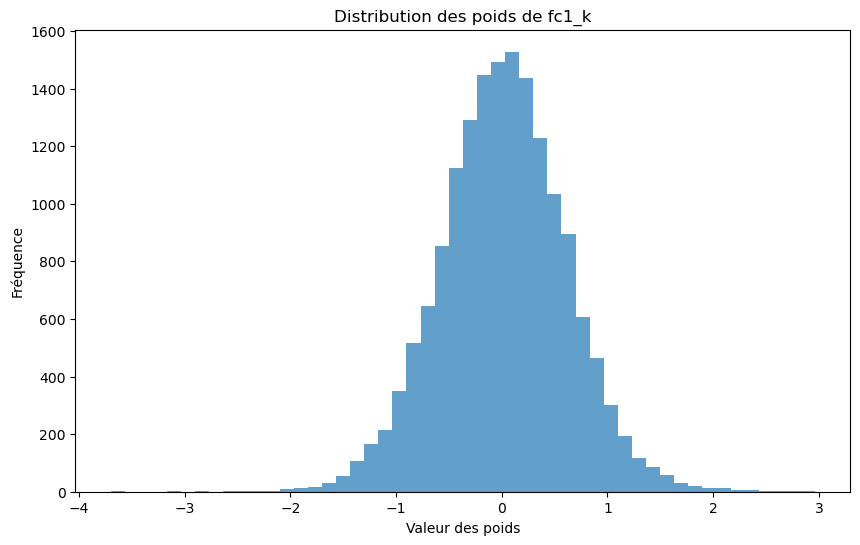

In [49]:
# Histogramme des poids de fc1_k
plt.figure(figsize=(10, 6))
plt.hist(fc1[0].detach().numpy().flatten(), bins=50, alpha=0.7)
plt.title("Distribution des poids de fc1_k")
plt.xlabel("Valeur des poids")
plt.ylabel("Fréquence")
plt.show()


In [50]:
fc1[0] == fc1_k_weights

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])